In [2]:
import torch
from torch import nn
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

### PyTorch model building essentials

PyTorch has four (give or take) essential modules you can use to create almost any kind of neural network you can imagine.

They are [`torch.nn`](https://pytorch.org/docs/stable/nn.html), [`torch.optim`](https://pytorch.org/docs/stable/optim.html), [`torch.utils.data.Dataset`](https://pytorch.org/docs/stable/data.html#torch.utils.data.Dataset) and [`torch.utils.data.DataLoader`](https://pytorch.org/docs/stable/data.html). For now, we'll focus on the first two and get to the other two later (though you may be able to guess what they do).

| PyTorch module | What does it do? |
| ----- | ----- |
| [`torch.nn`](https://pytorch.org/docs/stable/nn.html) | Contains all of the building blocks for computational graphs (essentially a series of computations executed in a particular way). |
| [`torch.nn.Parameter`](https://pytorch.org/docs/stable/generated/torch.nn.parameter.Parameter.html#parameter) | Stores tensors that can be used with `nn.Module`. If `requires_grad=True` gradients (used for updating model parameters via [**gradient descent**](https://ml-cheatsheet.readthedocs.io/en/latest/gradient_descent.html))  are calculated automatically, this is often referred to as "autograd".  | 
| [`torch.nn.Module`](https://pytorch.org/docs/stable/generated/torch.nn.Module.html#torch.nn.Module) | The base class for all neural network modules, all the building blocks for neural networks are subclasses. If you're building a neural network in PyTorch, your models should subclass `nn.Module`. Requires a `forward()` method be implemented. | 
| [`torch.optim`](https://pytorch.org/docs/stable/optim.html) | Contains various optimization algorithms (these tell the model parameters stored in `nn.Parameter` how to best change to improve gradient descent and in turn reduce the loss). | 
| `def forward()` | All `nn.Module` subclasses require a `forward()` method, this defines the computation that will take place on the data passed to the particular `nn.Module` (e.g. the linear regression formula above). |

If the above sounds complex, think of like this, almost everything in a PyTorch neural network comes from `torch.nn`,
* `nn.Module` contains the larger building blocks (layers)
* `nn.Parameter` contains the smaller parameters like weights and biases (put these together to make `nn.Module`(s))
* `forward()` tells the larger blocks how to make calculations on inputs (tensors full of data) within  `nn.Module`(s)
* `torch.optim` contains optimization methods on how to improve the parameters within `nn.Parameter` to better represent input data 

![a pytorch linear model with annotations](https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/images/01-pytorch-linear-model-annotated.png)
*Basic building blocks of creating a PyTorch model by subclassing `nn.Module`. For objects that subclass `nn.Module`, the `forward()` method must be defined.*

> **Resource:** See more of these essential modules and their use cases in the [PyTorch Cheat Sheet](https://pytorch.org/tutorials/beginner/ptcheat.html). 


## Creating some data using linear regression formula:

Formula => [Y = a + bX] , where X is the explanatory varriable and Y is the dependent variable. B is the slope and a is the intercept.

In [4]:
weight = 0.7
bias = 0.3

start = 0
end = 1
step = 0.02
X = torch.arange(start, end ,step).unsqueeze(dim =1)
y = weight * X + bias

X[:10], y[:10]

(tensor([[0.0000],
         [0.0200],
         [0.0400],
         [0.0600],
         [0.0800],
         [0.1000],
         [0.1200],
         [0.1400],
         [0.1600],
         [0.1800]]),
 tensor([[0.3000],
         [0.3140],
         [0.3280],
         [0.3420],
         [0.3560],
         [0.3700],
         [0.3840],
         [0.3980],
         [0.4120],
         [0.4260]]))

## Splitting the data:

In [5]:
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.2, random_state=43)

In [29]:
def plot_predictions(train_data=X_train, 
                     train_labels=y_train, 
                     test_data=X_test, 
                     test_labels=y_test, 
                     predictions=None):
  """
  Plots training data, test data and compares predictions.
  """
  plt.figure(figsize=(10, 7))

  # Plot training data in blue
  plt.scatter(train_data, train_labels, c="b", s=4, label="Training data")
  
  # Plot test data in green
  plt.scatter(test_data, test_labels, c="g", s=4, label="Testing data")

  if predictions is not None:
    # Plot the predictions in red (predictions were made on the test data)
    plt.scatter(test_data, predictions, c="r", s=4, label="Predictions")

  # Show the legend
  plt.legend(prop={"size": 14});

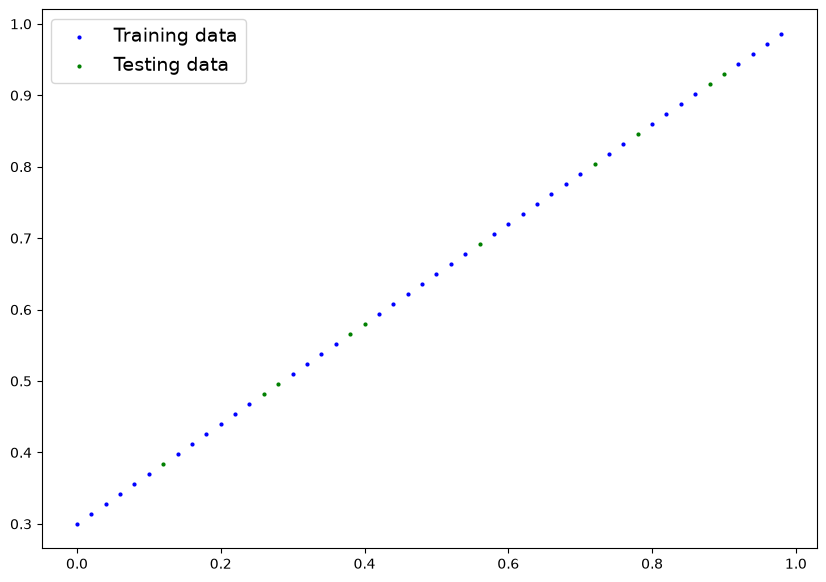

In [30]:
plot_predictions()

In [11]:
print(X_train.shape, len(X_train))
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

torch.Size([40, 1]) 40
torch.Size([10, 1])
torch.Size([40, 1])
torch.Size([10, 1])


## Building Pytorch Model: [Linear Regression]:

> Uses OOPs concepts like Inheritance!!

In [26]:
class LR(nn.Module): # nn.Module act as BaseModel from pydantic, It contains all items needed for creating Neural Networks.
    def __init__(self):
        super().__init__()

        self.weight = nn.Parameter(torch.randn(
            1, 
            requires_grad = True,
            dtype = torch.float32
        ))
        """Allows PyTorch to track the gradients of the given parameter(in this case Bias), which is used by torch.autograd() and Gradient Descent to find the optiomal values of Weight and Bias.
        It is activeby default!"""
        self.bias = nn.Parameter(torch.randn(
            1,
            requires_grad=True, 
            dtype = torch.float32
        ))

        # Defining Forward Propagation:
        # This is the Main function, i.e, for each NN Algo will have it's own forward function which is defined by the user. In this the forward operation(Main operation) is Linear Regression
    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.weight * x + self.bias

### Checking the parameters of the Pytorch model:

The future goal is to reach the weight and bias values of 0.7 & 0.3

In [44]:
# Allows of a fixed random value used during a that instance.
torch.manual_seed(42)

model_1 = LR()

model_1.state_dict()

OrderedDict([('weight', tensor([0.3367])), ('bias', tensor([0.1288]))])

### Performing Prediction:

In [35]:
y_preds = model_1(X_test)

y_preds

tensor([[0.2568],
        [0.3712],
        [0.3174],
        [0.2231],
        [0.2635],
        [0.4318],
        [0.3914],
        [0.1692],
        [0.2163],
        [0.4251]], grad_fn=<AddBackward0>)

In [ ]:
with torch.inference_mode(): # Hides the grad_fn element from output .no_grad() does the same thing
    y_preds = model_1(X_test)

y_preds

tensor([[0.2568],
        [0.3712],
        [0.3174],
        [0.2231],
        [0.2635],
        [0.4318],
        [0.3914],
        [0.1692],
        [0.2163],
        [0.4251]])

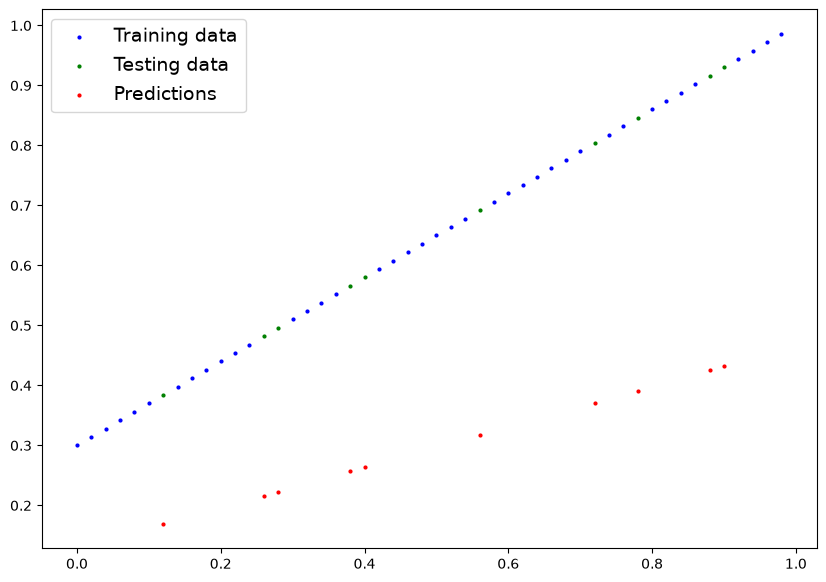

In [34]:
plot_predictions(predictions=y_preds)

## Training the Model:


* Right now our model is making predictions using random parameters to make calculations, it's basically guessing (randomly).
* To fix that, we can update its internal parameters (I also refer to *parameters* as patterns), the `weights` and `bias` values we set randomly using `nn.Parameter()` and `torch.randn()` to be something that better represents the data.

### Creating a loss function and optimizer in PyTorch

For our model to update its parameters on its own, we'll need to add a few more things to our recipe.

And that's a **loss function** as well as an **optimizer**.

The rolls of these are: 

| Function | What does it do? | Where does it live in PyTorch? | Common values |
| ----- | ----- | ----- | ----- |
| **Loss function** | Measures how wrong your model's predictions (e.g. `y_preds`) are compared to the truth labels (e.g. `y_test`). Lower the better. | PyTorch has plenty of built-in loss functions in [`torch.nn`](https://pytorch.org/docs/stable/nn.html#loss-functions). | Mean absolute error (MAE) for regression problems ([`torch.nn.L1Loss()`](https://pytorch.org/docs/stable/generated/torch.nn.L1Loss.html)). Binary cross entropy for binary classification problems ([`torch.nn.BCELoss()`](https://pytorch.org/docs/stable/generated/torch.nn.BCELoss.html)).  |
| **Optimizer** | Tells your model how to update its internal parameters to best lower the loss. | You can find various optimization function implementations in [`torch.optim`](https://pytorch.org/docs/stable/optim.html). | Stochastic gradient descent ([`torch.optim.SGD()`](https://pytorch.org/docs/stable/generated/torch.optim.SGD.html#torch.optim.SGD)). Adam optimizer ([`torch.optim.Adam()`](https://pytorch.org/docs/stable/generated/torch.optim.Adam.html#torch.optim.Adam)). | 


In [ ]:
loss_func = nn.L1Loss() # Calculates Loss

optimizer_func = torch.optim.SGD( # Stochastic gradient Descent, tries to find a way to reduce the loss or adjust the parameters to minimize the loss( it could by increasing or decreasing the weight/bias value.)
    params = model_1.parameters(),
    lr = 0.01 ) # Learning rate